In [1]:
# Stage 1: fire/smoke image classifier (4 classes: none, smoke, fire, both)
# Run this first. Checks the working folder so the paths below (Dataset_fire/train/ ...) work unchanged.
import os
os.makedirs('models', exist_ok=True)
print('Working folder:', os.getcwd())
print('Contains:', os.listdir('.'))

Working folder: d:\Y3 S1\Project Practicum\DFire_detection
Contains: ['build_fire_dataset.py', 'Dataset_fire', 'DFire', 'Fire_Stage1_CNN.ipynb', 'history_fire.csv', 'models']


In [2]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.preprocessing import image
from tensorflow.keras.utils import plot_model
from pathlib import Path
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import tensorflow as tf
import pandas as pd
import numpy as np
import cv2
import os

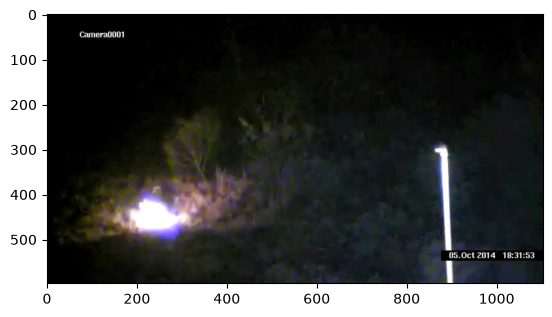

In [34]:
# CHANGED: path now points to a fire image
sample = 'Dataset_fire/train/fire/' + sorted(os.listdir('Dataset_fire/train/fire'))[0]
img = image.load_img(sample)
plt.imshow(img)

In [4]:
cv2.imread(sample).shape  #height, width, and channels of image

(598, 1103, 3)

### Check the labels before training
Shows 4 random images per class. Look at them: do the `fire` images show flames and the `smoke` images show smoke?
If fire and smoke look swapped, change `SMOKE_ID` and `FIRE_ID` in `build_fire_dataset.py`, delete `Dataset_fire/`, and rebuild.

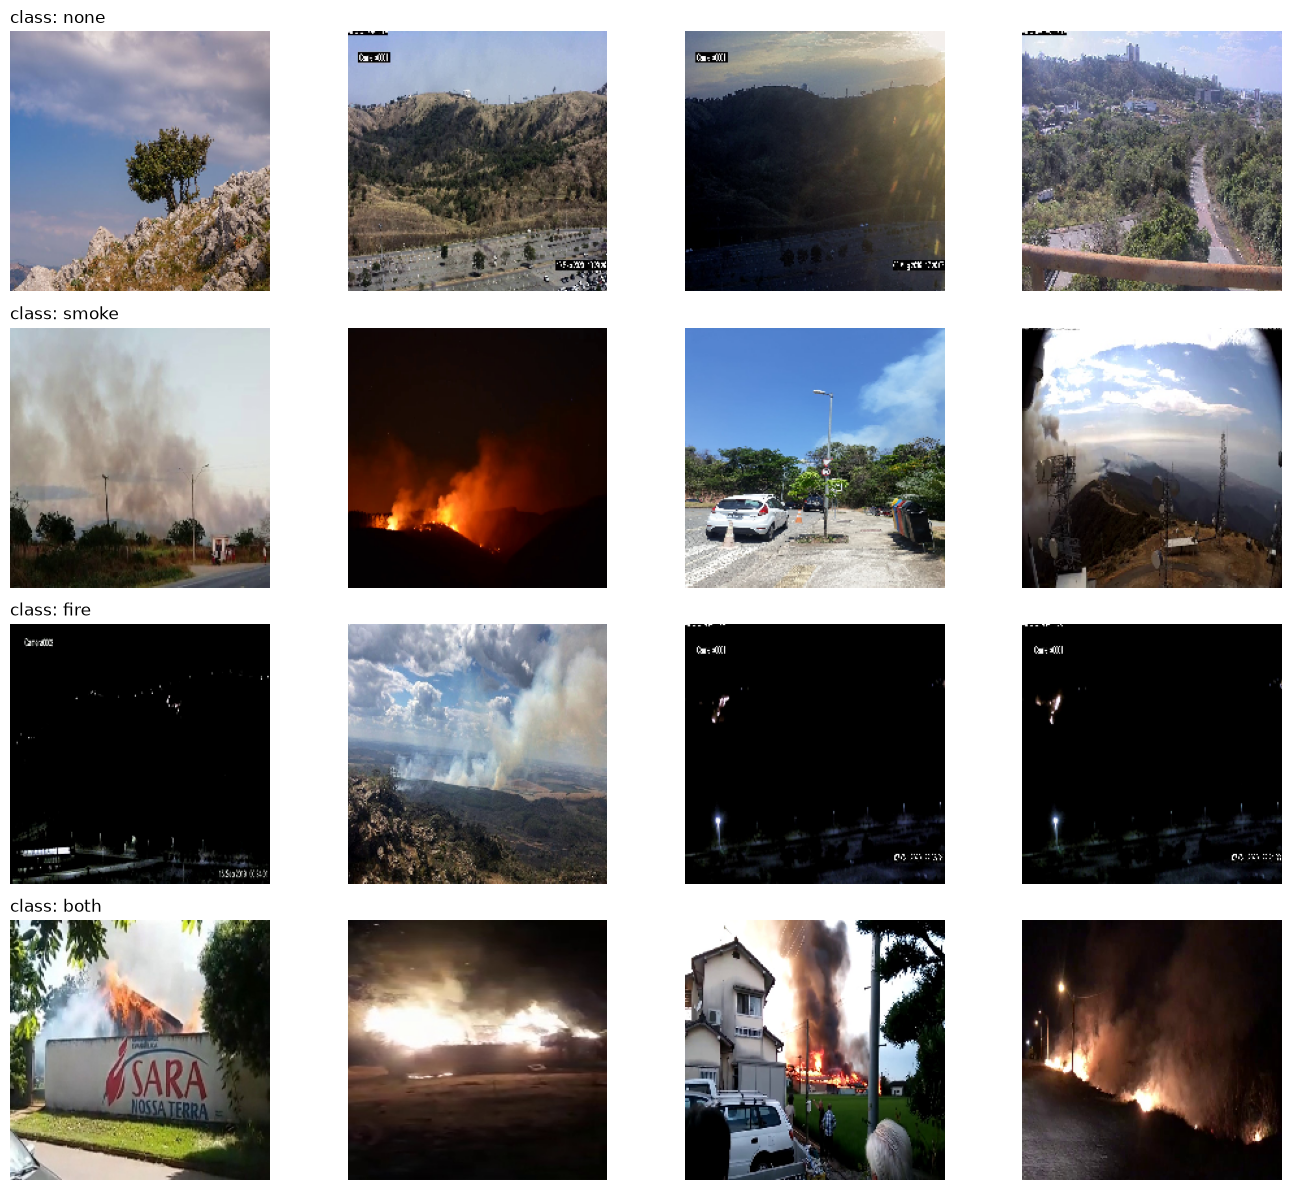

In [5]:
# ADDED: visual check of the labels (run after the sample-image cells)
import random
classes_to_check = ['none', 'smoke', 'fire', 'both']
plt.figure(figsize=(14, 12))
for r, c in enumerate(classes_to_check):
    folder = f'Dataset_fire/train/{c}'
    for k, f in enumerate(random.sample(os.listdir(folder), 4)):
        plt.subplot(4, 4, r * 4 + k + 1)
        plt.imshow(image.load_img(os.path.join(folder, f), target_size=(200, 200)))
        plt.axis('off')
        if k == 0:
            plt.title(f'class: {c}', loc='left', fontsize=12)
plt.tight_layout()
plt.show()

In [6]:
train = ImageDataGenerator(rescale=1/255)
validation = ImageDataGenerator(rescale=1/255)

In [7]:
train_dataset = train.flow_from_directory('Dataset_fire/train/',
                                           target_size= (200,200),
                                           classes=['none', 'smoke', 'fire', 'both'],  # CHANGED
                                           batch_size= 10,
                                           class_mode='categorical')  # CHANGED: 4 classes, not binary

validation_dataset = validation.flow_from_directory('Dataset_fire/validation/',
                                           target_size= (200,200),
                                           classes=['none', 'smoke', 'fire', 'both'],  # CHANGED
                                           batch_size= 10,
                                           class_mode='categorical')  # CHANGED: 4 classes, not binary

Found 5393 images belonging to 4 classes.
Found 951 images belonging to 4 classes.


### Class weights
The `none` class has many more images than `fire`. Weights make mistakes on small classes count more during training.

In [8]:
# ADDED: class weights for the imbalanced classes
from sklearn.utils.class_weight import compute_class_weight
w = compute_class_weight('balanced', classes=np.arange(len(train_dataset.class_indices)), y=train_dataset.classes)
class_weight = dict(enumerate(w))
print(train_dataset.class_indices)
print({k: round(v, 2) for k, v in class_weight.items()})

{'none': 0, 'smoke': 1, 'fire': 2, 'both': 3}
{0: np.float64(0.88), 1: np.float64(0.88), 2: np.float64(1.68), 3: np.float64(0.88)}


In [9]:
model = tf.keras.models.Sequential([tf.keras.layers.Conv2D(16,(3,3),activation = 'relu', input_shape = (200,200,3)),
                                    tf.keras.layers.MaxPooling2D(2,2),
                                    
                                    tf.keras.layers.Conv2D(32,(3,3),activation = 'relu'),
                                    tf.keras.layers.MaxPooling2D(2,2),
                                    
                                    tf.keras.layers.Conv2D(64,(3,3),activation = 'relu'),
                                    tf.keras.layers.MaxPooling2D(2,2),
                                    
                                    tf.keras.layers.Flatten(),
                                    tf.keras.layers.Dense(512, activation='relu'),
                                    tf.keras.layers.Dense(4, activation='softmax')
                                    
                                   ])

c:\Users\engso_ypbkrg7\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [10]:
model.compile(loss='categorical_crossentropy',  # CHANGED
              optimizer= 'adam',
              metrics=['accuracy'])

In [11]:
model_fit = model.fit(train_dataset,
                      validation_data = validation_dataset,
                      epochs = 10,
                      class_weight = class_weight,   # ADDED: 'both' and 'fire' have fewer images than 'none'
                      batch_size= 100,
                      callbacks=[tf.keras.callbacks.CSVLogger('history_fire.csv')],
                      shuffle = True)
_, accuracy = model.evaluate(train_dataset, steps=len(train_dataset), batch_size= 10)
print(f"Test accuracy: {round(accuracy * 100, 2)}%")

Epoch 1/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 114s 210ms/step - accuracy: 0.5320 - loss: 1.0304 - val_accuracy: 0.6004 - val_loss: 0.9447
Epoch 2/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 49s 90ms/step - accuracy: 0.6740 - loss: 0.7517 - val_accuracy: 0.7119 - val_loss: 0.7350
Epoch 3/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 54s 99ms/step - accuracy: 0.7853 - loss: 0.5259 - val_accuracy: 0.7035 - val_loss: 0.7884
Epoch 4/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 56s 104ms/step - accuracy: 0.8760 - loss: 0.3312 - val_accuracy: 0.7171 - val_loss: 0.9057
Epoch 5/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 58s 108ms/step - accuracy: 0.9232 - loss: 0.2225 - val_accuracy: 0.7361 - val_loss: 1.1492
Epoch 6/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 60s 111ms/step - accuracy: 0.9499 - loss: 0.1511 - val_accuracy: 0.6951 - val_loss: 1.4642
Epoch 7/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 53s 98ms/step - accuracy: 0.9622 - loss: 0.1079 - val_accuracy: 0.7266 - val_loss: 1.3272
Epoch 8/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 53s 98ms/step - accuracy: 0.9716 - loss: 0.08

In [12]:
his = pd.read_csv('history_fire.csv') 
his.head(10)

,epoch,accuracy,loss,val_accuracy,val_loss
0,0,0.531986,1.030423,0.600421,0.944703
1,1,0.674022,0.751715,0.711882,0.735049
2,2,0.785277,0.525942,0.703470,0.788434
3,3,0.875950,0.331237,0.717140,0.905711
4,4,0.923234,0.222539,0.736067,1.149183
5,5,0.949935,0.151055,0.695058,1.464237
6,6,0.962173,0.107935,0.726604,1.327230
7,7,0.971630,0.086387,0.728707,1.215859
8,8,0.974782,0.078351,0.729758,1.699152
9,9,0.977007,0.070418,0.688749,1.804732


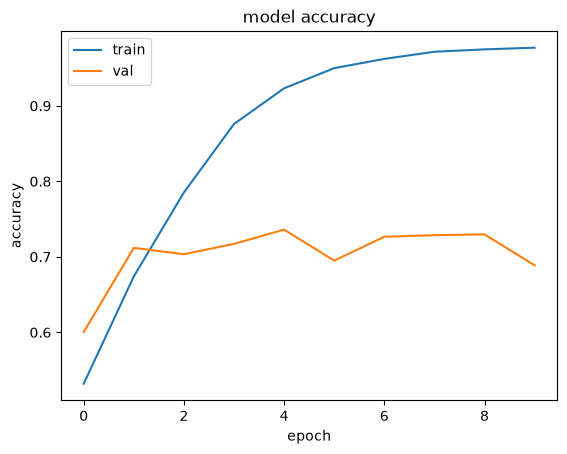

In [13]:
plt.plot(model_fit.history['accuracy'])
plt.plot(model_fit.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

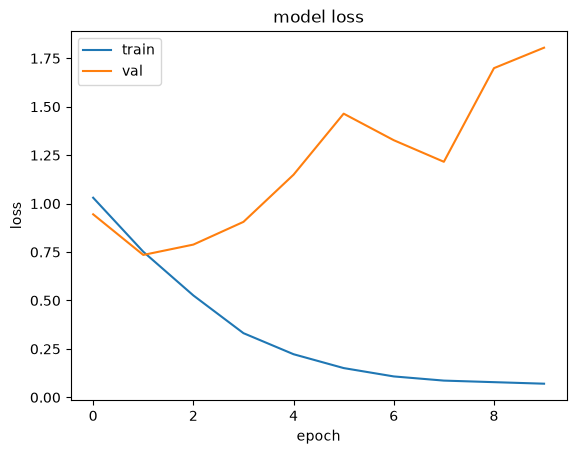

In [14]:
plt.plot(model_fit.history['loss'])
plt.plot(model_fit.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

In [15]:

fig = make_subplots(specs=[[{"secondary_y": True}]])

# Add traces
fig.add_trace(
    go.Scatter( y=model_fit.history['val_loss'], name="val_loss"),
    secondary_y=False)

fig.add_trace(
    go.Scatter( y=model_fit.history['loss'], name="loss"),
    secondary_y=False)

fig.add_trace(
    go.Scatter( y=model_fit.history['val_accuracy'], name="val_accuracy"),
    secondary_y=True)

fig.add_trace(
    go.Scatter( y=model_fit.history['accuracy'], name="accuracy"),
    secondary_y=True)

# Add figure title
fig.update_layout(
    title_text="Loss/Accuracy of Conv2D Model")

# Set x-axis title
fig.update_xaxes(title_text="Number of Epochs")

# Set y-axes titles
fig.update_yaxes(title_text="<b>primary</b> Loss", secondary_y=False)
fig.update_yaxes(title_text="<b>secondary</b> Accuracy", secondary_y=True)

fig.show()

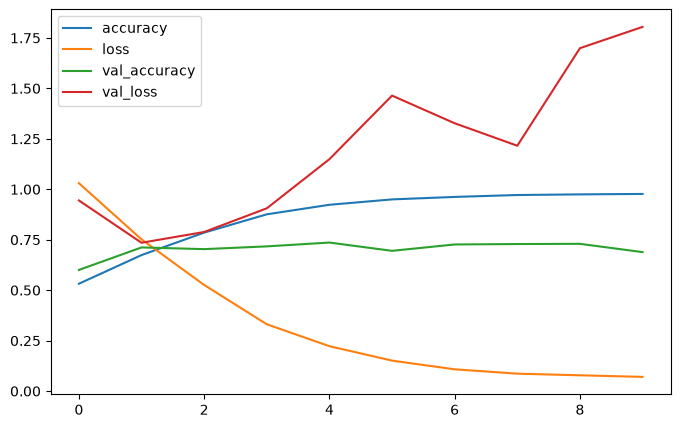

In [16]:
pd.DataFrame(model_fit.history).plot(figsize=(8,5))
plt.show()

In [17]:
model.summary() #Detail of model

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 198, 198, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 99, 99, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 97, 97, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 46, 46, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 33856)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    17,334,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,081,262 (198.67 MB)

 Trainable params: 17,360,420 (66.22 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 34,720,842 (132.45 MB)

In [35]:
pip install pydot

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [37]:
plot_model(model, to_file = 'convlstm_model_structure_plot.png', show_shapes = True, show_layer_names = True)

You must install pydot (`pip install pydot`) for `plot_model` to work.


In [39]:
# Save the fire/smoke model under its own name
model.save('models/fire_cnn_stage1.h5')

In [40]:
validation_dataset.class_indices

{'none': 0, 'smoke': 1, 'fire': 2, 'both': 3}

Found 1420 images belonging to 4 classes.
142/142 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step - accuracy: 0.7014 - loss: 1.8724
Real test accuracy: 70.14%
142/142 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step
              precision    recall  f1-score   support

        none       0.78      0.72      0.75       400
       smoke       0.84      0.59      0.70       400
        fire       0.60      0.75      0.67       220
        both       0.62      0.77      0.68       400

    accuracy                           0.70      1420
   macro avg       0.71      0.71      0.70      1420
weighted avg       0.72      0.70      0.70      1420



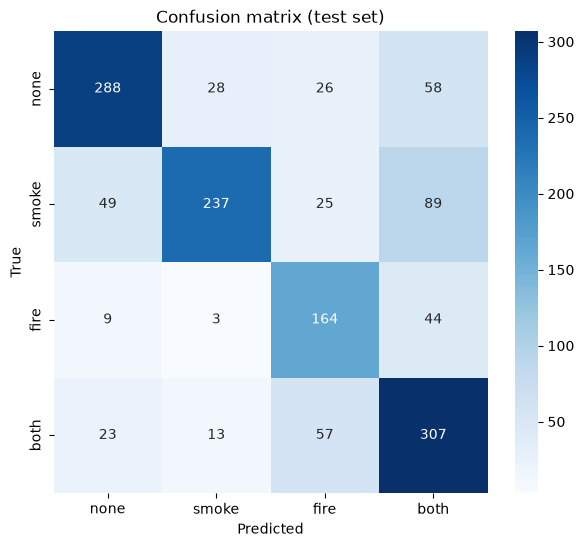

In [41]:
# ADDED: real test-set evaluation.
# The "Test accuracy" printed after training above is measured on the TRAINING data, so it is not a true test score.
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

class_names = ['none', 'smoke', 'fire', 'both']
test = ImageDataGenerator(rescale=1/255)
test_dataset = test.flow_from_directory('Dataset_fire/test/',
                                        target_size= (200,200),
                                        classes=class_names,
                                        batch_size= 10,
                                        class_mode='categorical',
                                        shuffle=False)   # shuffle=False so predictions line up with labels

test_loss, test_acc = model.evaluate(test_dataset)
print(f"Real test accuracy: {round(test_acc * 100, 2)}%")

y_pred = np.argmax(model.predict(test_dataset), axis=1)
print(classification_report(test_dataset.classes, y_pred, target_names=class_names))

cm = confusion_matrix(test_dataset.classes, y_pred)
plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix (test set)')
plt.show()

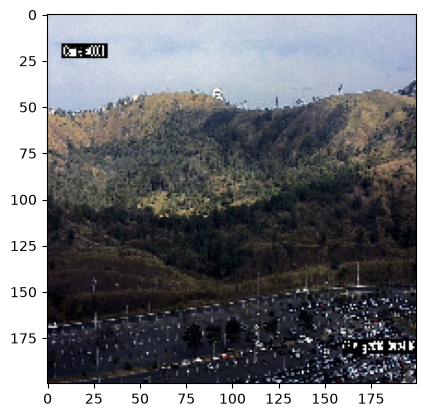

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 828ms/step
True class: none | This is both


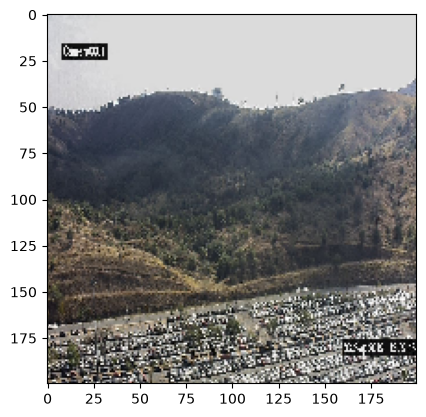

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 665ms/step
True class: none | This is none


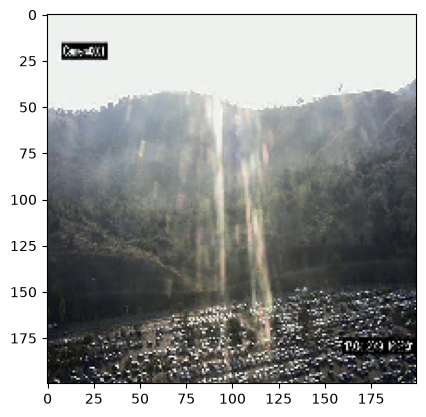

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 745ms/step
True class: none | This is none


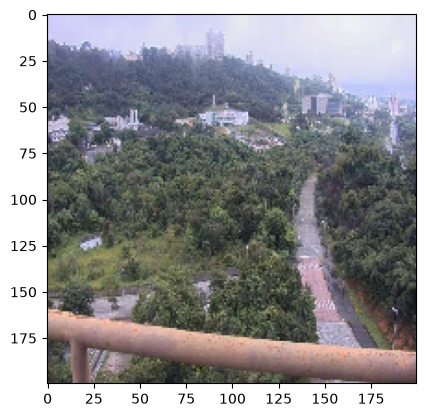

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 760ms/step
True class: smoke | This is none


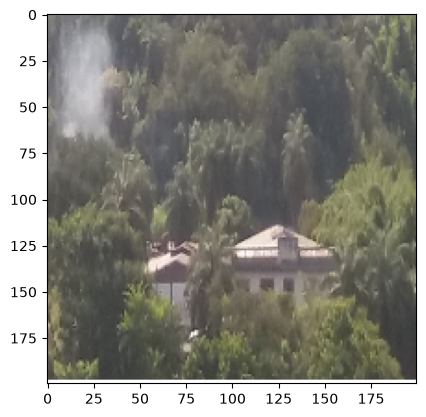

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 827ms/step
True class: smoke | This is none


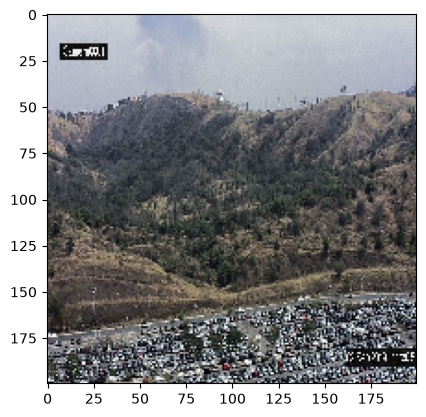

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 926ms/step
True class: smoke | This is both


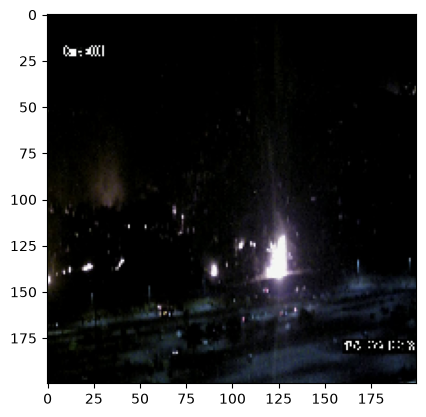

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 838ms/step
True class: fire | This is fire


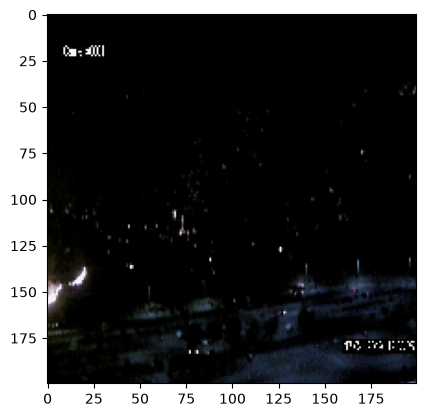

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 849ms/step
True class: fire | This is fire


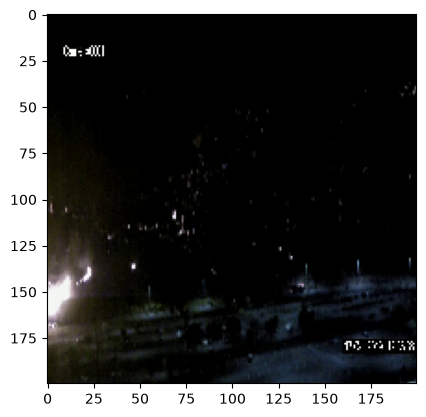

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 840ms/step
True class: fire | This is fire


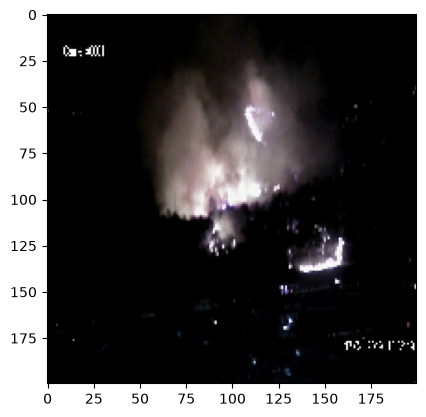

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 794ms/step
True class: both | This is both


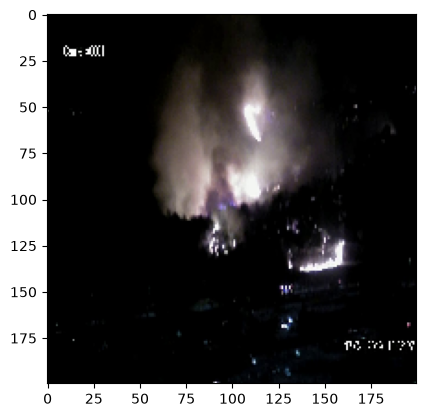

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 770ms/step
True class: both | This is both


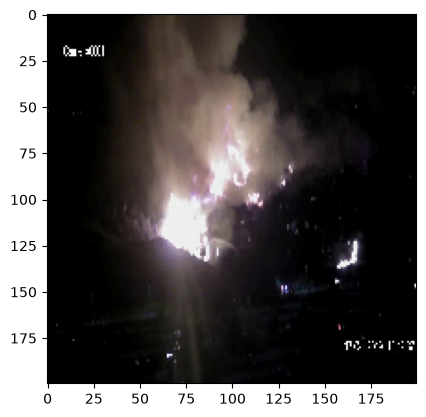

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 802ms/step
True class: both | This is both


In [22]:
dir_path = 'Dataset_fire/test' #parht of images that you want to test
class_names = ['none', 'smoke', 'fire', 'both']  # CHANGED

for c in class_names:                                    # CHANGED: test folder now has one subfolder per class
    for i in sorted(os.listdir(dir_path + '/' + c))[:3]:  # CHANGED: first 3 images per class, to keep output short
        img = image.load_img(dir_path + '/' + c + '/' + i, target_size= (200,200, 3))
        plt.imshow(img)
        plt.show()
        
        X = image.img_to_array(img)
        X = X / 255                                      # CHANGED: model was trained on images rescaled by 1/255
        X = np.expand_dims(X, axis=0)
        images = np.vstack([X])
        val = model.predict(images)
        
        picture = class_names[np.argmax(val)]            # CHANGED: pick the class with the highest probability
            
        print("True class:", c, "| This is", picture)

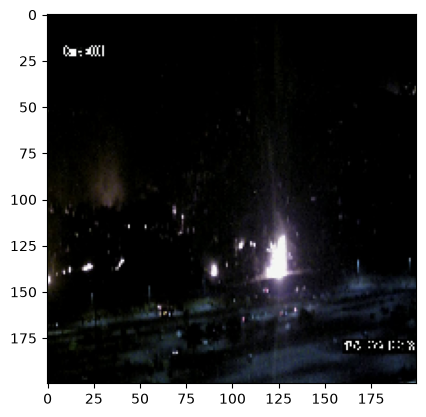

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 817ms/step
99.7300033569336% is fire


In [23]:
#path of image that you want to predics correct class
# CHANGED: replace with the path of your own photo if you like
path = 'Dataset_fire/test/fire/' + sorted(os.listdir('Dataset_fire/test/fire'))[0]
img = image.load_img(path, target_size= (200,200, 3))
plt.imshow(img)
plt.show()
    
X = image.img_to_array(img)
X = X / 255                                              # CHANGED: same rescaling as training
X = np.expand_dims(X, axis=0)
images = np.vstack([X])
val = model.predict(images)

picture = class_names[np.argmax(val)]                    # CHANGED
        
print(f"{round(np.max(val) * 100, 2)}%","is" , picture)  # CHANGED: model's confidence for this image

In [24]:
from tensorflow.keras.models import load_model
new_model = load_model('models/fire_cnn_stage1.h5')

In [25]:
new_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 198, 198, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 99, 99, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 97, 97, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 46, 46, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 33856)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    17,334,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,360,422 (66.22 MB)

 Trainable params: 17,360,420 (66.22 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [38]:
from pathlib import Path

def list_stems(txt):
    return {Path(l.strip().replace('\\', '/')).stem
            for l in Path(txt).read_text().splitlines() if l.strip()}

def folder_stems(root):
    return {p.stem for p in Path(root).rglob('*')
            if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}}

train_list = list_stems('DFire_splits/dfire_train.txt')
test_list  = list_stems('DFire_splits/dfire_test.txt')
mine_train = folder_stems('Dataset_fire/train') | folder_stems('Dataset_fire/validation')
mine_test  = folder_stems('Dataset_fire/test')

print('My train+val:', len(mine_train), '| in dfire_train.txt:', len(mine_train & train_list),
      '| in dfire_test.txt:', len(mine_train & test_list))
print('My test     :', len(mine_test),  '| in dfire_test.txt:', len(mine_test & test_list),
      '| in dfire_train.txt:', len(mine_test & train_list))

FileNotFoundError: [Errno 2] No such file or directory: 'DFire_splits\\dfire_train.txt'